<a href="https://colab.research.google.com/github/Lulukia0704/portofolio-data-analisis/blob/main/01-dashboard-penjualan/Project01_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#JUDUL DAN TUJUAN

abcd..


##1. Persiapan


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

WARNA = "#1F5868"  # warna utama dashboard Excel

def rupiah(x):
    """Ubah angka jadi format Rp dengan titik ribuan."""
    return "Rp" + f"{x:,.0f}".replace(",", ".")

##2. Import Data

In [16]:
URL = "https://raw.githubusercontent.com/Lulukia0704/portofolio-data-analisis/main/01-dashboard-penjualan/data.csv"

try:
    df = pd.read_csv(URL, parse_dates=["Tanggal"])
except Exception:
    df = pd.read_csv("data.csv", parse_dates=["Tanggal"])  # cadangan jika URL gagal

df.head()

,Tanggal,Cabang,Kategori Produk,Jumlah,Total Omset
0,2026-01-01,Surabaya,Kesehatan & Kecantikan,2,195100
1,2026-01-03,Jakarta,Kesehatan & Kecantikan,3,311300
2,2026-01-09,Surabaya,Perabotan Rumah,3,687400
3,2026-01-12,Bandung,Makanan & Minuman,3,117000
4,2026-01-14,Jakarta,Perabotan Rumah,3,683300


## 3. Cek Kualitas Data

In [17]:
print("Jumlah baris, kolom :", df.shape)
print("Periode             :", df["Tanggal"].min().date(), "sampai", df["Tanggal"].max().date())
print("Data kosong         :", int(df.isna().sum().sum()))
print("Baris duplikat      :", int(df.duplicated().sum()))
df.dtypes

Jumlah baris, kolom : (80, 5)
Periode             : 2026-01-01 sampai 2026-06-29
Data kosong         : 0
Baris duplikat      : 0


,0
Tanggal,datetime64[ns]
Cabang,object
Kategori Produk,object
Jumlah,int64
Total Omset,int64


## 4. Hitung Ulang Angka Dashboard

In [18]:
df["Bulan"] = df["Tanggal"].dt.to_period("M")
NAMA_BULAN = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun"}

total_omset = df["Total Omset"].sum()
jml_transaksi = len(df)

per_cabang = df.groupby("Cabang")["Total Omset"].sum().sort_values(ascending=False)
per_kategori = df.groupby("Kategori Produk")["Total Omset"].sum().sort_values(ascending=False)
per_bulan = df.groupby("Bulan")["Total Omset"].sum()
per_bulan.index = [NAMA_BULAN[p.month] for p in per_bulan.index]

print("Total omset      :", rupiah(total_omset))
print("Jumlah transaksi :", jml_transaksi)
print("Cabang terbesar  :", per_cabang.index[0])
print()
print(per_cabang.map(rupiah).to_string())
print()
print(per_kategori.map(rupiah).to_string())
print()
print(per_bulan.map(rupiah).to_string())

Total omset      : Rp59.388.600
Jumlah transaksi : 80
Cabang terbesar  : Bandung

Cabang
Bandung     Rp17.479.200
Jakarta     Rp16.252.500
Surabaya    Rp13.798.300
Medan       Rp11.858.600

Kategori Produk
Elektronik                Rp35.204.200
Fashion                    Rp7.989.600
Perabotan Rumah            Rp7.251.200
Kesehatan & Kecantikan     Rp5.334.800
Makanan & Minuman          Rp3.608.800

Jan     Rp8.487.600
Feb    Rp14.951.600
Mar    Rp12.972.700
Apr     Rp3.117.600
Mei    Rp10.648.000
Jun     Rp9.211.100


## 5. Pencocokan dengan Excel

In [19]:
excel = {
    "Total omset": 59_388_600, "Jumlah transaksi": 80,
    "Bandung": 17_479_200, "Jakarta": 16_252_500, "Surabaya": 13_798_300, "Medan": 11_858_600,
    "Elektronik": 35_204_200, "Fashion": 7_989_600, "Perabotan Rumah": 7_251_200,
    "Kesehatan & Kecantikan": 5_334_800, "Makanan & Minuman": 3_608_800,
    "Jan": 8_487_600, "Feb": 14_951_600, "Mar": 12_972_700,
    "Apr": 3_117_600, "Mei": 10_648_000, "Jun": 9_211_100,
}

python = {"Total omset": total_omset, "Jumlah transaksi": jml_transaksi}
python.update(per_cabang.to_dict())
python.update(per_kategori.to_dict())
python.update(per_bulan.to_dict())

hasil = pd.DataFrame({"Excel": excel, "Python": python})
hasil["Cocok"] = hasil["Excel"] == hasil["Python"]
print("Semua angka cocok dengan Excel:", bool(hasil["Cocok"].all()))
hasil

Semua angka cocok dengan Excel: True


,Excel,Python,Cocok
Total omset,59388600,59388600,True
Jumlah transaksi,80,80,True
Bandung,17479200,17479200,True
Jakarta,16252500,16252500,True
Surabaya,13798300,13798300,True
Medan,11858600,11858600,True
Elektronik,35204200,35204200,True
Fashion,7989600,7989600,True
Perabotan Rumah,7251200,7251200,True
Kesehatan & Kecantikan,5334800,5334800,True


## 6. Eksplorasi Tambahan

6.1 Ukuran dasar per transaksi

In [20]:
print("Rata-rata per transaksi :", rupiah(df["Total Omset"].mean()))
print("Median per transaksi    :", rupiah(df["Total Omset"].median()))
print("Transaksi terkecil      :", rupiah(df["Total Omset"].min()))
print("Transaksi terbesar      :", rupiah(df["Total Omset"].max()))

Rata-rata per transaksi : Rp742.358
Median per transaksi    : Rp466.450
Transaksi terkecil      : Rp67.000
Transaksi terbesar      : Rp2.767.200


6.2 Kontribusi tiap kategori

In [21]:
kat = df.groupby("Kategori Produk").agg(
    transaksi=("Total Omset", "count"),
    omset=("Total Omset", "sum"),
    rata_rata=("Total Omset", "mean"),
).sort_values("omset", ascending=False)
kat["porsi_omset_%"] = (kat["omset"] / kat["omset"].sum() * 100).round(1)
kat["porsi_transaksi_%"] = (kat["transaksi"] / kat["transaksi"].sum() * 100).round(1)
kat.round({"rata_rata": 0, "porsi_omset_%": 1, "porsi_transaksi_%": 1})

,transaksi,omset,rata_rata,porsi_omset_%,porsi_transaksi_%
Kategori Produk,,,,,
Elektronik,20,35204200,1760210.0,59.3,25.0
Fashion,14,7989600,570686.0,13.5,17.5
Perabotan Rumah,12,7251200,604267.0,12.2,15.0
Kesehatan & Kecantikan,18,5334800,296378.0,9.0,22.5
Makanan & Minuman,16,3608800,225550.0,6.1,20.0


6.3 Perubahan omset bulan ke bulan

In [22]:
perubahan = pd.DataFrame({
    "omset": per_bulan,
    "transaksi": df.groupby(df["Tanggal"].dt.month).size().rename(index=NAMA_BULAN),
})
perubahan["perubahan_%"] = (perubahan["omset"].pct_change() * 100).round(1)
perubahan

,omset,transaksi,perubahan_%
Jan,8487600,17,NaN
Feb,14951600,14,76.2
Mar,12972700,13,-13.2
Apr,3117600,8,-76.0
Mei,10648000,13,241.5
Jun,9211100,15,-13.5


6.4 Outlier (metode IQR)

In [23]:
q1, q3 = df["Total Omset"].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
outlier = df[df["Total Omset"] > batas_atas].sort_values("Total Omset", ascending=False)

print("Batas atas outlier :", rupiah(batas_atas))
print("Jumlah outlier     :", len(outlier))
print("Kategori outlier   :", outlier["Kategori Produk"].unique().tolist())
outlier[["Tanggal", "Cabang", "Kategori Produk", "Jumlah", "Total Omset"]]

Batas atas outlier : Rp1.873.850
Jumlah outlier     : 9
Kategori outlier   : ['Elektronik']


,Tanggal,Cabang,Kategori Produk,Jumlah,Total Omset
28,2026-02-27,Bandung,Elektronik,3,2767200
35,2026-03-17,Bandung,Elektronik,3,2764000
61,2026-05-26,Jakarta,Elektronik,3,2604800
43,2026-03-30,Surabaya,Elektronik,3,2587900
24,2026-02-18,Jakarta,Elektronik,3,2569800
17,2026-02-01,Medan,Elektronik,3,2481900
69,2026-06-13,Jakarta,Elektronik,3,2470300
31,2026-03-02,Medan,Elektronik,3,2452000
53,2026-05-09,Bandung,Elektronik,3,2346100


6.5 Mengapa omset April anjlok?

In [24]:
bulan_num = df["Tanggal"].dt.month
elektronik = df[df["Kategori Produk"] == "Elektronik"]

pembanding = pd.DataFrame({
    "omset_total": df.groupby(bulan_num)["Total Omset"].sum(),
    "omset_elektronik": elektronik.groupby(elektronik["Tanggal"].dt.month)["Total Omset"].sum(),
    "transaksi_elektronik": elektronik.groupby(elektronik["Tanggal"].dt.month).size(),
}).fillna(0).astype(int)
pembanding["omset_non_elektronik"] = pembanding["omset_total"] - pembanding["omset_elektronik"]
pembanding.index = [NAMA_BULAN[m] for m in pembanding.index]
pembanding

,omset_total,omset_elektronik,transaksi_elektronik,omset_non_elektronik
Jan,8487600,2735100,3,5752500
Feb,14951600,11298500,6,3653100
Mar,12972700,9375000,4,3597700
Apr,3117600,0,0,3117600
Mei,10648000,6664600,4,3983400
Jun,9211100,5131000,3,4080100


(6.6): perbandingan cabang

In [25]:
cabang = df.groupby("Cabang").agg(
    transaksi=("Total Omset", "count"),
    omset=("Total Omset", "sum"),
    rata_rata=("Total Omset", "mean"),
).sort_values("omset", ascending=False)
cabang.round({"rata_rata": 0})

,transaksi,omset,rata_rata
Cabang,,,
Bandung,24,17479200,728300.0
Jakarta,19,16252500,855395.0
Surabaya,22,13798300,627195.0
Medan,15,11858600,790573.0


## 7. Grafik

7.1 Omset per cabang dan per kategori

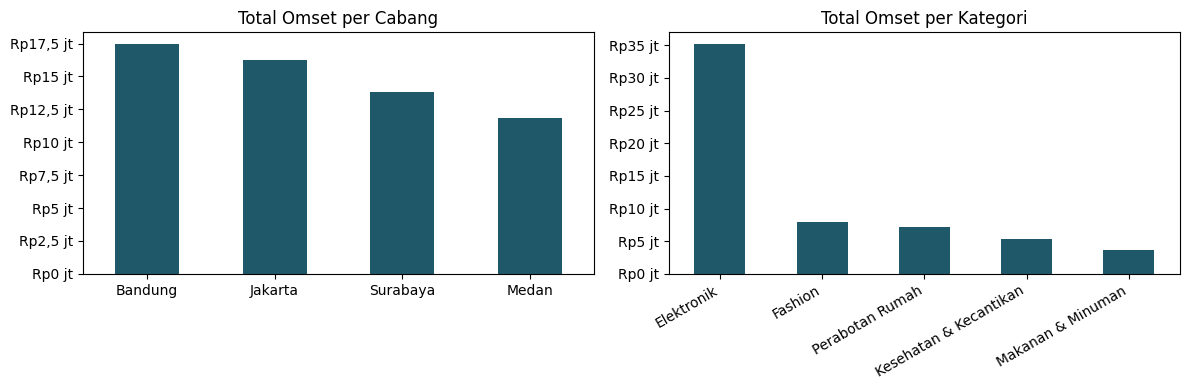

In [26]:
juta = FuncFormatter(lambda x, _: "Rp" + f"{x/1e6:g}".replace(".", ",") + " jt")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

per_cabang.plot.bar(ax=ax[0], color=WARNA)
ax[0].set_title("Total Omset per Cabang")
ax[0].yaxis.set_major_formatter(juta)
ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=0)

per_kategori.plot.bar(ax=ax[1], color=WARNA)
ax[1].set_title("Total Omset per Kategori")
ax[1].yaxis.set_major_formatter(juta)
ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=30)
for lbl in ax[1].get_xticklabels():
    lbl.set_ha("right")

plt.tight_layout()
plt.show()

7.2 Tren bulanan dan Elektronik vs kategori lain

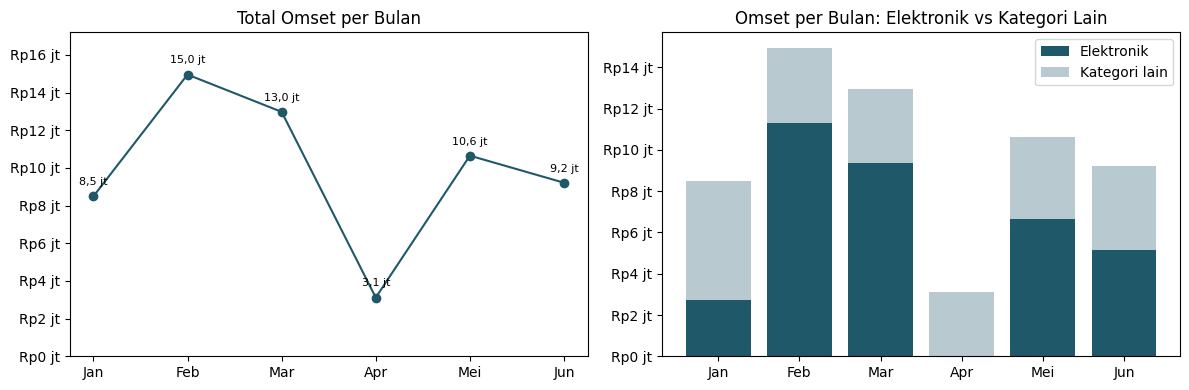

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(per_bulan.index, per_bulan.values, marker="o", color=WARNA)
ax[0].set_title("Total Omset per Bulan")
ax[0].set_ylim(0, per_bulan.max() * 1.15)
ax[0].yaxis.set_major_formatter(juta)
for x, y in zip(per_bulan.index, per_bulan.values):
    ax[0].annotate(f"{y/1e6:.1f}".replace(".", ",") + " jt", (x, y),
                   textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)

ax[1].bar(pembanding.index, pembanding["omset_elektronik"], color=WARNA, label="Elektronik")
ax[1].bar(pembanding.index, pembanding["omset_non_elektronik"],
          bottom=pembanding["omset_elektronik"], color="#B8C9CF", label="Kategori lain")
ax[1].set_title("Omset per Bulan: Elektronik vs Kategori Lain")
ax[1].yaxis.set_major_formatter(juta)
ax[1].legend()

plt.tight_layout()
plt.show()

## 8. Insight & Rekomendasi

Temuan

1. Total omset Januari-Juni 2026 adalah Rp59.388.600 dari 80 transaksi; hasil Python sama dengan Excel (17 dari 17 angka cocok).
2. Bandung cabang terbesar (Rp17.479.200, sekitar 29%) karena jumlah transaksinya paling banyak (24). Jakarta punya nilai rata-rata per transaksi tertinggi (sekitar Rp855 ribu).
3. Elektronik menyumbang 59,3% omset dari hanya 25% transaksi; semua 9 transaksi outlier berasal dari kategori ini.
4. Omset April anjlok 76% dari Maret (Rp3.117.600), dan pada April tidak ada transaksi Elektronik. Kenaikan Mei (+241,5%) hanyalah pemulihan dari dasar rendah.

Dugaan penyebab (belum dibuktikan oleh data)
Tidak adanya Elektronik di April bisa karena stok kosong, promosi yang berakhir, atau pola musiman. Data 80 baris tidak cukup untuk memastikannya.

Rekomendasi

1. Periksa stok dan promosi Elektronik pada April sebagai penyebab utama penurunan.
2. Kurangi ketergantungan pada satu kategori dengan mendorong penjualan kategori lain (misalnya Fashion dan Perabotan Rumah).
3. Pantau jumlah transaksi Elektronik tiap bulan sebagai indikator dini penurunan omset.
4. Untuk Jakarta, tingkatkan jumlah transaksi (misalnya lewat promosi), karena nilai per transaksinya sudah tinggi.

Keterbatasan: data fiktif, 80 baris, dan hanya 6 bulan, jadi kesimpulan bersifat ilustrasi analisis.